# Tugas - Klasifikasi dengan Artificial Neural Network (ANN)

| Nama | NRP |
|------|-----|
| Lioneil Diyoel Trystan Tikupadang | 5054251037 |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model ANN (Multi-Layer Perceptron) Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja ANN secara praktik, khususnya:
1. Perbedaan hasil antar fungsi aktivasi (ReLU, Tanh, Logistic/Sigmoid)
2. Pengaruh ukuran arsitektur (`hidden_layer_sizes`) dan jumlah iterasi terhadap gejala overfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model ANN dengan arsitektur dasar.
   - Lakukan eksperimen fungsi aktivasi dan regularisasi arsitektur.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [33]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neural_network import MLPClassifier


In [34]:
# Load dataset dan tampilkan informasi dasar: jumlah baris dan kolom, tipe data, statistik deskriptif, dan jumlah missing value.
dataset = "data/telco_customer.csv"
df = pd.read_csv(dataset)

df.columns = df.columns.str.strip()

print("Jumlah baris :", df.shape[0])
print("Jumlah kolom :", df.shape[1])

print("\nTipe data:")
print(df.dtypes.value_counts())

print("\nInformasi dataset:")
df.info()

print("\nStatistik deskriptif:")
display(df.describe().T)

print("\nTotal missing value:", df.isna().sum().sum())

Jumlah baris : 7043
Jumlah kolom : 21

Tipe data:
str        18
int64       2
float64     1
Name: count, dtype: int64

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  Streaming

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75



Total missing value: 0


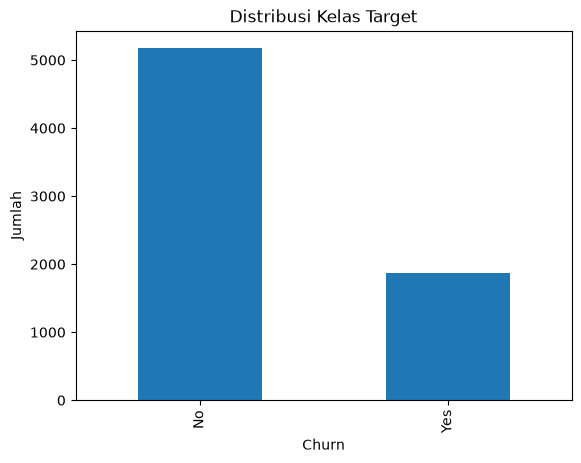

In [35]:
# Tampilkan distribusi kelas target dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.


df['Churn'].value_counts().plot(kind='bar')
plt.xlabel('Churn')
plt.ylabel('Jumlah')
plt.title('Distribusi Kelas Target')
plt.show()

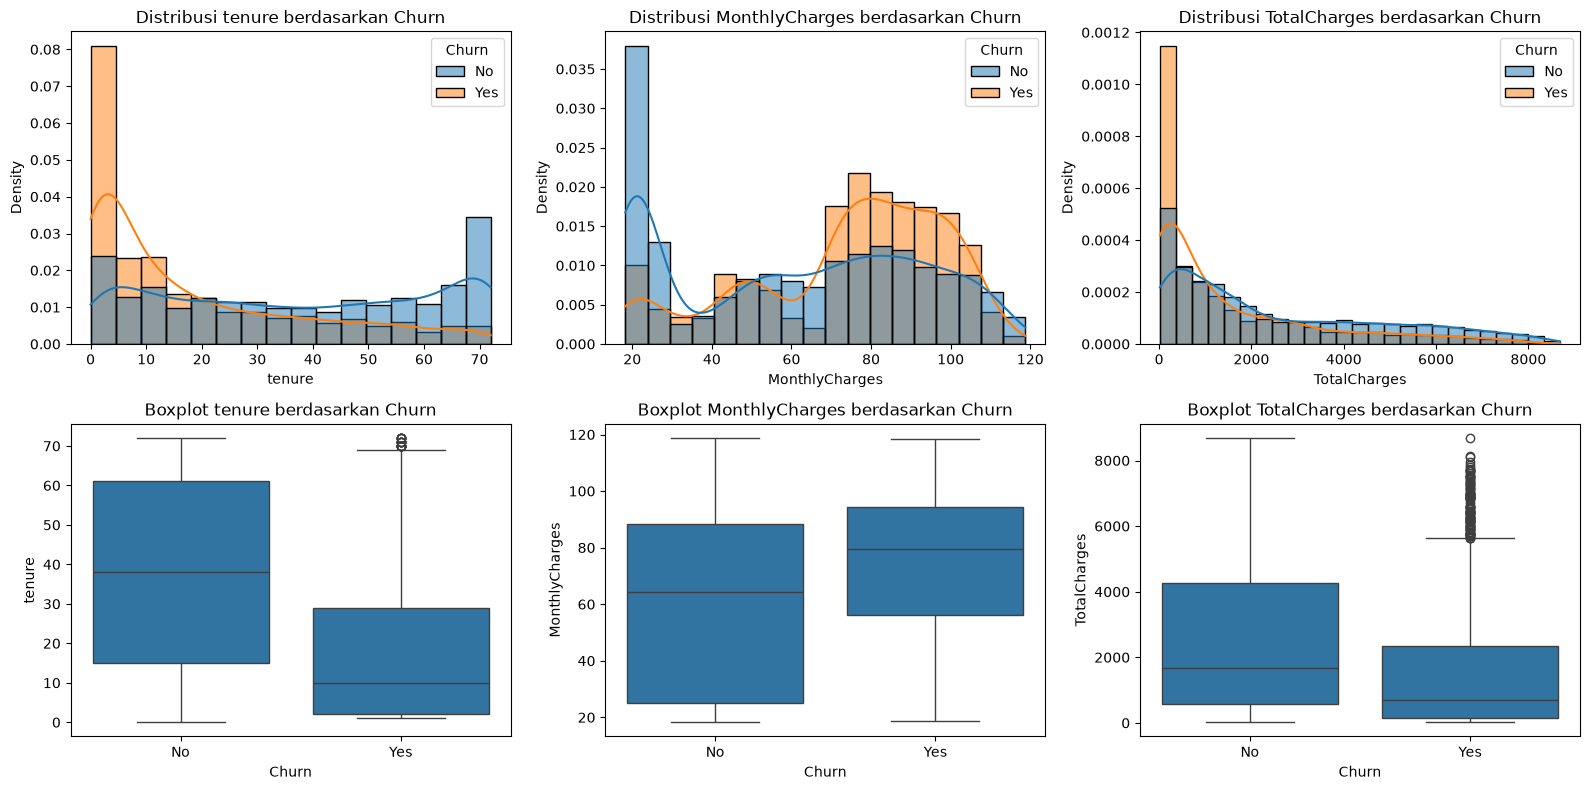

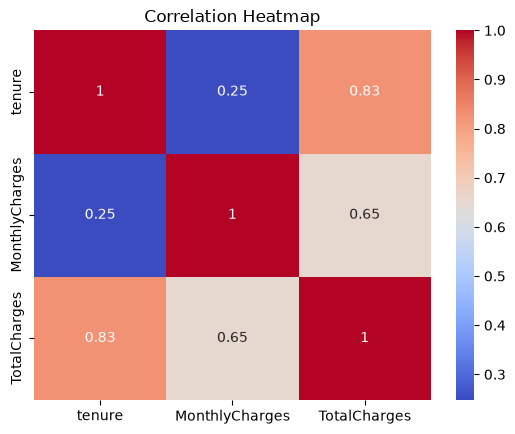

In [36]:
# Tampilkan distribusi atau hubungan antar fitur (histogram, boxplot, atau correlation heatmap), dibedakan berdasarkan kelas target.

df_eda = df.copy()
df_eda['TotalCharges'] = pd.to_numeric(df_eda['TotalCharges'], errors='coerce')

num_cols_eda = ['tenure', 'MonthlyCharges', 'TotalCharges']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for i, col in enumerate(num_cols_eda):
    sns.histplot(data=df_eda, x=col, hue='Churn', kde=True, stat='density', common_norm=False, ax=axes[0, i])
    axes[0, i].set_title(f'Distribusi {col} berdasarkan Churn')
    sns.boxplot(data=df_eda, x='Churn', y=col, ax=axes[1, i])
    axes[1, i].set_title(f'Boxplot {col} berdasarkan Churn')
plt.tight_layout()
plt.show()

corr = df_eda[['tenure', 'MonthlyCharges', 'TotalCharges']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

In [37]:
# Tangani missing value (jika ada) dengan strategi yang sesuai.
# Pastikan strategi yang dipilih tidak memperkenalkan data leakage.

# Cek missing value, sel berisi spasi kosong diubah ke numerik (nilai kosong menjadi NaN).
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("Missing value per kolom (setelah konversi):")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nBaris yang TotalCharges-nya kosong:")
display(df.loc[df['TotalCharges'].isna(), ['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

df['TotalCharges'] = df['TotalCharges'].fillna(0.0)
print("\nTotal missing value setelah imputasi:", df.isna().sum().sum())

df = df.drop(columns=['customerID'])


Missing value per kolom (setelah konversi):
TotalCharges    11
dtype: int64

Baris yang TotalCharges-nya kosong:


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,NaN,No
753,3115-CZMZD,0,20.25,NaN,No
936,5709-LVOEQ,0,80.85,NaN,No
1082,4367-NUYAO,0,25.75,NaN,No
1340,1371-DWPAZ,0,56.05,NaN,No
3331,7644-OMVMY,0,19.85,NaN,No
3826,3213-VVOLG,0,25.35,NaN,No
4380,2520-SGTTA,0,20.00,NaN,No
5218,2923-ARZLG,0,19.70,NaN,No
6670,4075-WKNIU,0,73.35,NaN,No



Total missing value setelah imputasi: 0


In [38]:
# Jika terdapat fitur kategorikal, lakukan encoding yang sesuai (misalnya One-Hot Encoding atau Ordinal Encoding).

# Encode target: Yes -> 1 (churn), No -> 0
df['Churn'] = df['Churn'].map({'No': 0, 'Yes': 1})

# One-Hot Encoding untuk seluruh fitur kategorikal
cat_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
print("Fitur kategorikal:", cat_cols)

df_encoded = pd.get_dummies(df, columns=cat_cols, drop_first=True, dtype=int)
print("\nUkuran data setelah encoding:", df_encoded.shape)
display(df_encoded.head())


Fitur kategorikal: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Ukuran data setelah encoding: (7043, 31)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,1,0,0,1,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,0,1,0,0,1,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,0,1,0,0,0,1,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,1,0,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0


In [39]:
# Pisahkan fitur (X) dan target (y).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.

from sklearn.model_selection import train_test_split

X = df_encoded.drop(columns=['Churn'])
y = df_encoded['Churn']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Ukuran X_train:", X_train.shape, "| X_test:", X_test.shape)
print("\nProporsi kelas (train):")
print(y_train.value_counts(normalize=True).round(4))
print("\nProporsi kelas (test):")
print(y_test.value_counts(normalize=True).round(4))

Ukuran X_train: (5634, 30) | X_test: (1409, 30)

Proporsi kelas (train):
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64

Proporsi kelas (test):
Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64


**Catatan penting:** Sama seperti SVM, ANN juga menghitung penjumlahan berbobot dari fitur-fiturnya, sehingga fitur dengan rentang nilai besar bisa mendominasi proses training dan membuat konvergensi lebih lambat atau tidak stabil. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [51]:
# Lakukan feature scaling (StandardScaler) pada fitur numerik.
# fit_transform pada X_train, transform saja pada X_test.

from sklearn.preprocessing import StandardScaler

# Hanya fitur numerik kontinu yang discaling
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])   # fit hanya pada train
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])         # test hanya di-transform

print("Mean fitur numerik (train, setelah scaling):")
print(X_train_scaled[num_cols].mean().round(4))
print("\nStd fitur numerik (train, setelah scaling):")
print(X_train_scaled[num_cols].std().round(4))

Mean fitur numerik (train, setelah scaling):
tenure           -0.0
MonthlyCharges   -0.0
TotalCharges      0.0
dtype: float64

Std fitur numerik (train, setelah scaling):
tenure            1.0001
MonthlyCharges    1.0001
TotalCharges      1.0001
dtype: float64


# 3. Eksperimen Model

## 3.1 ANN dengan Arsitektur Dasar

Bangun model MLPClassifier sederhana dengan satu hidden layer sebagai baseline.

In [52]:
# Inisialisasi dan latih model MLPClassifier dengan satu hidden layer (misalnya hidden_layer_sizes=(10,))
# dan activation='relu' menggunakan train set (yang sudah discaling).

mlp_base = MLPClassifier(hidden_layer_sizes=(10,), activation='relu', max_iter=500, random_state=42)
mlp_base.fit(X_train_scaled, y_train)

print("Jumlah iterasi aktual :", mlp_base.n_iter_)
print("Loss akhir            :", round(mlp_base.loss_, 4))
print("Akurasi train         :", round(mlp_base.score(X_train_scaled, y_train), 4))

Jumlah iterasi aktual : 326
Loss akhir            : 0.3934
Akurasi train         : 0.817


In [53]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label untuk keperluan evaluasi.

y_pred_base = mlp_base.predict(X_test_scaled)

from sklearn.metrics import accuracy_score
print("Akurasi test (baseline):", round(accuracy_score(y_test, y_pred_base), 4))
print("Contoh 10 prediksi pertama:", y_pred_base[:10])

Akurasi test (baseline): 0.797
Contoh 10 prediksi pertama: [0 1 0 0 0 1 0 0 0 0]


## 3.2 Eksperimen Fungsi Aktivasi

Fungsi aktivasi menentukan bagaimana neuron "mengaktivasikan" keluarannya dan memungkinkan model mempelajari pola non-linear. Bandingkan beberapa pilihan fungsi aktivasi yang tersedia di scikit-learn.

In [54]:
# Latih beberapa model MLPClassifier dengan arsitektur yang sama, tetapi activation berbeda:
# 'relu', 'tanh', dan 'logistic'.
# Gunakan hyperparameter lain yang sama (hidden_layer_sizes, max_iter, random_state) agar perbandingan adil.

activations = ['relu', 'tanh', 'logistic']
act_models = {}

for act in activations:
    m = MLPClassifier(hidden_layer_sizes=(10,), activation=act, max_iter=500, random_state=42)
    m.fit(X_train_scaled, y_train)
    act_models[act] = m
    print(f"activation = {act:8s} | iterasi aktual = {m.n_iter_:3d} | loss akhir = {m.loss_:.4f}")

activation = relu     | iterasi aktual = 326 | loss akhir = 0.3934


c:\Users\Lio\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


activation = tanh     | iterasi aktual = 500 | loss akhir = 0.3879
activation = logistic | iterasi aktual = 153 | loss akhir = 0.4113


In [55]:
# Hitung dan bandingkan akurasi test set dari ketiga fungsi aktivasi tersebut.
# Sajikan dalam tabel perbandingan.

rows = []
for act, m in act_models.items():
    rows.append({
        'Activation': act,
        'Akurasi Train': accuracy_score(y_train, m.predict(X_train_scaled)),
        'Akurasi Test': accuracy_score(y_test, m.predict(X_test_scaled)),
        'Iterasi Aktual': m.n_iter_,
        'Loss Akhir': m.loss_,
    })

df_act = pd.DataFrame(rows).set_index('Activation')
df_act['Selisih (Train - Test)'] = df_act['Akurasi Train'] - df_act['Akurasi Test']
display(df_act.round(4))

best_act = df_act['Akurasi Test'].idxmax()
print(f"\nActivation terbaik berdasarkan akurasi test: {best_act} ({df_act.loc[best_act, 'Akurasi Test']:.4f})")


,Akurasi Train,Akurasi Test,Iterasi Aktual,Loss Akhir,Selisih (Train - Test)
Activation,,,,,
relu,0.8170,0.7970,326,0.3934,0.0200
tanh,0.8225,0.7864,500,0.3879,0.0361
logistic,0.8062,0.8013,153,0.4113,0.0049



Activation terbaik berdasarkan akurasi test: logistic (0.8013)


## 3.3 Eksperimen Regularisasi: Pengaruh Ukuran Arsitektur terhadap Overfitting

Semakin besar/dalam arsitektur ANN (jumlah neuron dan hidden layer), semakin besar kapasitas model untuk menghafal data training. Pada bagian ini kalian akan mengamati bagaimana perubahan ukuran arsitektur memengaruhi akurasi training dan testing.

In [56]:
# Latih beberapa model MLPClassifier dengan variasi hidden_layer_sizes,
# misalnya (2,), (5,), (10,), (50,), (100, 50).
# Gunakan activation terbaik dari hasil eksperimen 3.2, dan hyperparameter lain yang sama.

architectures = [(2,), (5,), (10,), (50,), (100, 50)]
arch_models = {}

for arch in architectures:
    m = MLPClassifier(hidden_layer_sizes=arch, activation=best_act, max_iter=500, random_state=42)
    m.fit(X_train_scaled, y_train)
    arch_models[arch] = m
    print(f"hidden_layer_sizes = {str(arch):9s} | iterasi aktual = {m.n_iter_:3d} | loss akhir = {m.loss_:.4f}")

hidden_layer_sizes = (2,)      | iterasi aktual = 195 | loss akhir = 0.4148
hidden_layer_sizes = (5,)      | iterasi aktual = 211 | loss akhir = 0.4104
hidden_layer_sizes = (10,)     | iterasi aktual = 153 | loss akhir = 0.4113
hidden_layer_sizes = (50,)     | iterasi aktual = 154 | loss akhir = 0.4106
hidden_layer_sizes = (100, 50) | iterasi aktual = 115 | loss akhir = 0.4120


In [58]:
# Hitung akurasi pada train set dan test set untuk setiap arsitektur yang dicoba.
# Simpan hasilnya dalam list atau dictionary agar mudah diplot.

arch_results = []
for arch, m in arch_models.items():
    arch_results.append({
        'Arsitektur': str(arch),
        'Jumlah Parameter': sum(w.size for w in m.coefs_) + sum(b.size for b in m.intercepts_),
        'Akurasi Train': accuracy_score(y_train, m.predict(X_train_scaled)),
        'Akurasi Test': accuracy_score(y_test, m.predict(X_test_scaled)),
    })

df_arch = pd.DataFrame(arch_results)
df_arch['Gap (Train - Test)'] = df_arch['Akurasi Train'] - df_arch['Akurasi Test']
display(df_arch.round(4))

,Arsitektur,Jumlah Parameter,Akurasi Train,Akurasi Test,Gap (Train - Test)
0,"(2,)",65,0.8033,0.7991,0.0042
1,"(5,)",161,0.8069,0.7977,0.0092
2,"(10,)",321,0.8062,0.8013,0.0049
3,"(50,)",1601,0.8072,0.8062,0.0010
4,"(100, 50)",8201,0.8064,0.8034,0.0029


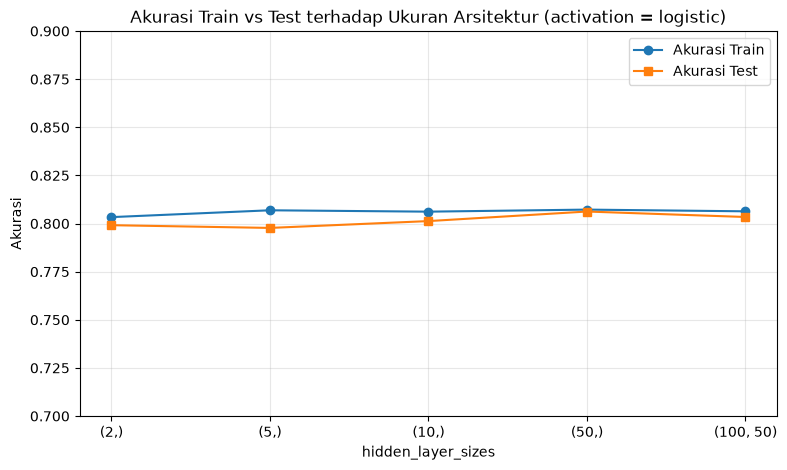

In [61]:
# Plot grafik akurasi training vs testing terhadap ukuran arsitektur dalam satu chart.
# Amati pada arsitektur seberapa besar model mulai menunjukkan gejala overfitting
# (akurasi training terus naik, sementara akurasi testing mulai stagnan atau menurun).

plt.figure(figsize=(9, 5))
plt.plot(df_arch['Arsitektur'], df_arch['Akurasi Train'], marker='o', label='Akurasi Train')
plt.plot(df_arch['Arsitektur'], df_arch['Akurasi Test'], marker='s', label='Akurasi Test')
plt.xlabel('hidden_layer_sizes')
plt.ylabel('Akurasi')
plt.ylim(0.70, 0.90)   
plt.title(f'Akurasi Train vs Test terhadap Ukuran Arsitektur (activation = {best_act})')
plt.grid(alpha=0.3)
plt.legend()
plt.show()


# 4. Evaluasi Model

In [62]:
# Tampilkan metrik evaluasi (Accuracy, Precision, Recall, F1-Score) untuk model dengan performa terbaik dari tiap eksperimen (3.2 dan 3.3).
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

from sklearn.metrics import precision_score, recall_score, f1_score

def eval_row(name, model):
    pred = model.predict(X_test_scaled)
    return {
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),
        'F1-Score': f1_score(y_test, pred),
    }

best_arch = df_arch.loc[df_arch['Akurasi Test'].idxmax(), 'Arsitektur']
best_arch_key = [a for a in arch_models if str(a) == best_arch][0]

eval_table = pd.DataFrame([
    eval_row(f'Eksperimen 3.2 - activation={best_act}, (10,)', act_models[best_act]),
    eval_row(f'Eksperimen 3.3 - activation={best_act}, {best_arch}', arch_models[best_arch_key]),
]).set_index('Model')
display(eval_table.round(4))

# Model terbaik secara keseluruhan (berdasarkan akurasi test)
if eval_table['Accuracy'].iloc[0] >= eval_table['Accuracy'].iloc[1]:
    best_model, best_name = act_models[best_act], eval_table.index[0]
else:
    best_model, best_name = arch_models[best_arch_key], eval_table.index[1]
print("Model terbaik secara keseluruhan:", best_name)


,Accuracy,Precision,Recall,F1-Score
Model,,,,
"Eksperimen 3.2 - activation=logistic, (10,)",0.8013,0.6516,0.5401,0.5906
"Eksperimen 3.3 - activation=logistic, (50,)",0.8062,0.6624,0.5508,0.6015


Model terbaik secara keseluruhan: Eksperimen 3.3 - activation=logistic, (50,)


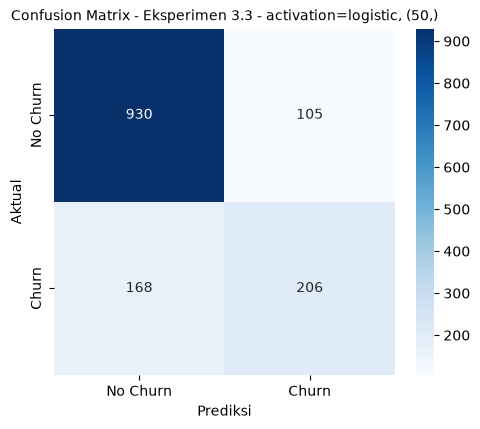

In [68]:
# Tampilkan Confusion Matrix untuk model dengan performa terbaik dalam bentuk heatmap.

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, best_model.predict(X_test_scaled))
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['No Churn', 'Churn'], yticklabels=['No Churn', 'Churn'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - ' + best_name, fontsize=10)
plt.show()

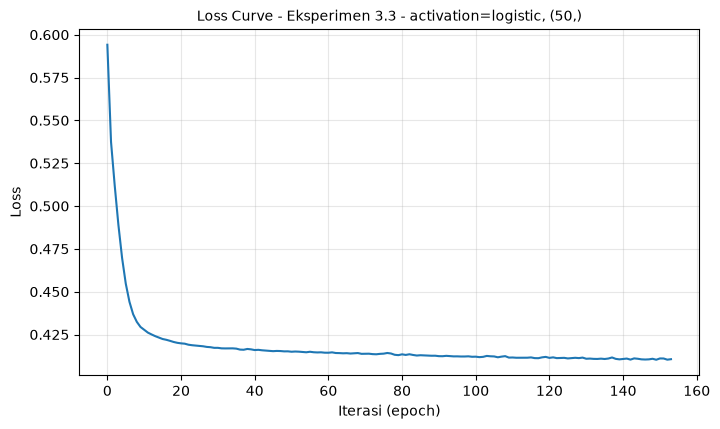

Iterasi aktual : 154 | max_iter : 500
Loss awal      : 0.5941
Loss akhir     : 0.4106


In [69]:
# Plot loss curve dari model dengan performa terbaik (atribut model.loss_curve_).
# Amati apakah loss sudah konvergen atau masih menurun saat max_iter tercapai.

plt.figure(figsize=(8, 4.5))
plt.plot(best_model.loss_curve_)
plt.xlabel('Iterasi (epoch)')
plt.ylabel('Loss')
plt.title('Loss Curve - ' + best_name, fontsize=10)
plt.grid(alpha=0.3)
plt.show()

print("Iterasi aktual :", best_model.n_iter_, "| max_iter :", best_model.max_iter)
print("Loss awal      :", round(best_model.loss_curve_[0], 4))
print("Loss akhir     :", round(best_model.loss_curve_[-1], 4))

# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan.

Beberapa hal yang perlu dibahas:
- Bandingkan performa ANN dengan fungsi aktivasi ReLU, Tanh, dan Logistic. Apakah hasilnya berbeda signifikan? Menurut kalian, kenapa demikian?
- Jelaskan temuan dari eksperimen regularisasi (ukuran arsitektur). Pada ukuran arsitektur berapa model mulai menunjukkan gejala overfitting? Bagaimana ciri-cirinya terlihat dari grafik akurasi training vs testing?
- Berdasarkan loss curve yang dihasilkan, apakah model sudah cukup konvergen? Apa yang akan kalian lakukan jika loss curve masih menurun tajam saat max_iter tercapai?

Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan, bukan hasil orang lain.

#### Hasil Analisis

**Setup eksperimen.** Seluruh model memakai `max_iter=500`, `random_state=42`, solver default (`adam`), dan data yang sudah di-scaling. Data dibagi 80:20 dengan `stratify=y` (train = 5.634 baris, test = 1.409 baris). Dataset imbalanced: 73,5% *No Churn* vs 26,5% *Churn*, sehingga model yang selalu menebak "tidak churn" sudah mencapai akurasi test sekitar 73,5%. Semua model di bawah ini berada di atas angka tersebut.

**1. Perbandingan fungsi aktivasi (arsitektur `(10,)`)**

| Activation | Akurasi Train | Akurasi Test | Selisih Train-Test | Iterasi Aktual | Loss Akhir |
|---|---|---|---|---|---|
| ReLU | 0,8170 | 0,7970 | 0,0200 | 326 | 0,3934 |
| Tanh | 0,8225 | 0,7864 | 0,0361 | 500 (belum konvergen) | 0,3879 |
| Logistic | 0,8062 | **0,8013** | 0,0049 | 153 | 0,4113 |

Akurasi test ketiganya berada pada rentang yang sempit (0,786 - 0,801), yaitu selisih sekitar 1,5 poin persen atau sekitar 21 dari 1.409 sampel uji. Karena hanya memakai satu `random_state` dan satu pembagian data, selisih sekecil ini **tidak bisa dikatakan signifikan**; urutan peringkatnya bisa saja berubah jika seed atau split diganti. Logistic memang unggul tipis pada akurasi test, tetapi itu bukan bukti bahwa fungsi aktivasi tersebut secara umum lebih baik.

Yang justru terlihat jelas adalah perbedaan *perilaku* training. ReLU dan Tanh mencapai loss training yang lebih rendah (0,393 dan 0,388) dan akurasi train yang lebih tinggi (0,817 dan 0,823), namun akurasi test mereka tidak ikut naik, sehingga selisih train-test lebih besar (0,020 dan 0,036). Tanh bahkan menampilkan *ConvergenceWarning* karena mencapai batas 500 iterasi sebelum konvergen. Sebaliknya, Logistic berhenti lebih awal (153 iterasi), loss-nya paling tinggi (0,411), tetapi generalisasinya paling stabil (selisih hanya 0,005). Penjelasan yang masuk akal: ReLU dan Tanh memiliki gradien yang lebih kuat sehingga lebih leluasa menyesuaikan diri dengan data train (termasuk noise), sedangkan sigmoid yang jenuh di kedua ujungnya cenderung menghasilkan fungsi yang lebih halus. Ini adalah dugaan berdasarkan pola angka di atas, bukan sesuatu yang diuji secara terpisah.

**2. Eksperimen ukuran arsitektur (activation = Logistic)**

| hidden_layer_sizes | Jumlah Parameter | Akurasi Train | Akurasi Test | Selisih |
|---|---|---|---|---|
| (2,) | 65 | 0,8033 | 0,7991 | 0,0042 |
| (5,) | 161 | 0,8069 | 0,7977 | 0,0092 |
| (10,) | 321 | 0,8062 | 0,8013 | 0,0049 |
| (50,) | 1.601 | 0,8072 | **0,8062** | 0,0010 |
| (100, 50) | 8.201 | 0,8064 | 0,8034 | 0,0029 |

Temuan utamanya: **pada rentang arsitektur yang diuji, saya tidak menemukan gejala overfitting yang jelas.** Ciri overfitting yang dicari adalah akurasi train yang terus naik sementara akurasi test stagnan atau turun. Pada grafik, akurasi train hampir datar di kisaran 0,803 - 0,807 walaupun jumlah parameter bertambah sekitar 126 kali lipat (65 menjadi 8.201), dan selisih train-test tetap di bawah 1 poin persen untuk semua ukuran. Selisih terbesar memang ada pada `(5,)` (0,0092), tetapi nilai itu tidak mengikuti ukuran arsitektur (arsitektur yang lebih besar justru memiliki selisih lebih kecil), jadi lebih tepat dianggap fluktuasi biasa daripada overfitting. Akurasi test tertinggi dicapai `(50,)` (0,8062), lalu turun sedikit ke 0,8034 pada `(100, 50)`; penurunan sebesar 0,0028 (sekitar 4 sampel) terlalu kecil untuk disimpulkan sebagai awal overfitting.

Kemungkinan penyebabnya (berdasarkan hasil di atas): (a) dengan activation Logistic, training berhenti otomatis setelah 115 - 211 iterasi, jauh sebelum `max_iter=500`, karena loss tidak membaik lagi melebihi `tol` selama 10 epoch berturut-turut, sehingga model tidak sempat "menghafal" data; dan (b) dataset tabular ini kemungkinan memiliki batas kemampuan prediksi di kisaran 80% akibat noise pada fitur, sehingga menambah kapasitas model tidak banyak membantu. Sebagai pembanding, pada eksperimen 3.2 kombinasi ReLU/Tanh dengan `(10,)` menunjukkan selisih train-test yang lebih besar (0,020 dan 0,036), yang menandakan bahwa kecenderungan overfitting lebih dipengaruhi oleh pilihan activation dan lamanya training daripada oleh jumlah neuron saja pada eksperimen ini.

**3. Evaluasi dan loss curve**

Model terbaik berdasarkan akurasi test adalah Logistic dengan `(50,)` (Accuracy 0,8062, Precision 0,6624, Recall 0,5508, F1 0,6015), sedikit di atas model terbaik eksperimen 3.2 (Logistic, `(10,)`: Accuracy 0,8013, Precision 0,6516, Recall 0,5401, F1 0,5906). Perlu dicatat bahwa akurasi yang tampak tinggi menyembunyikan kelemahan pada kelas minoritas: recall hanya sekitar 55%, artinya sekitar 45% pelanggan yang benar-benar churn tidak berhasil terdeteksi. Pemilihan model terbaik di sini juga dilakukan berdasarkan akurasi test (sesuai instruksi tugas), sehingga angka tersebut sedikit optimistis dibanding performa pada data yang benar-benar baru.

Loss curve model terbaik turun tajam dari sekitar 0,594 pada epoch pertama ke sekitar 0,43 dalam 10 epoch pertama, kemudian melandai dan relatif datar di kisaran 0,411 setelah sekitar 40 - 60 epoch (hanya berfluktuasi sekitar ±0,0005). Training berhenti pada iterasi ke-154, lebih awal dari `max_iter=500`, artinya penghentian terjadi karena kriteria `tol`, bukan karena batas iterasi habis. Jadi model **sudah cukup konvergen**. Jika loss curve masih menurun tajam saat `max_iter` tercapai, yang akan saya lakukan adalah: (1) menaikkan `max_iter` hingga kurva mendatar; (2) menyesuaikan `learning_rate_init` (menaikkannya bila turunnya terlalu lambat, menurunkannya bila kurva bergerigi); (3) memastikan scaling fitur sudah benar; dan (4) mengaktifkan `early_stopping=True` dengan validation set agar iterasi tambahan tidak berujung pada overfitting.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan.

Saran dapat berupa rekomendasi untuk eksperimen selanjutnya (misalnya mencoba solver lain seperti 'sgd', menambahkan regularisasi alpha, melakukan hyperparameter tuning dengan GridSearchCV, atau membandingkan dengan model lain), perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

#### Kesimpulan

1. Model ANN (MLPClassifier) berhasil mengklasifikasikan churn pelanggan Telco dengan akurasi test sekitar 0,79 - 0,81, di atas baseline mayoritas (sekitar 0,735). Model terbaik adalah activation Logistic dengan `hidden_layer_sizes=(50,)` (Accuracy 0,8062, F1-Score 0,6015).
2. Perbedaan akurasi test antar fungsi aktivasi (ReLU 0,7970, Tanh 0,7864, Logistic 0,8013) sangat kecil dan belum dapat dianggap signifikan karena hanya diuji dengan satu seed dan satu split. Perbedaan yang lebih nyata terlihat pada perilaku training: ReLU dan Tanh menghasilkan loss train lebih rendah tetapi selisih train-test lebih besar (0,020 dan 0,036), dan Tanh belum konvergen dalam 500 iterasi.
3. Pada eksperimen ukuran arsitektur (dari 65 hingga 8.201 parameter), tidak terlihat overfitting yang jelas: akurasi train datar (sekitar 0,806) dan selisih train-test selalu di bawah 1 poin persen. Hal ini kemungkinan besar karena training dengan activation Logistic berhenti otomatis lebih awal oleh kriteria `tol` dan karena batas informasi pada dataset ini.
4. Loss curve model terbaik sudah mendatar dan training berhenti sebelum `max_iter`, sehingga model dapat dikatakan konvergen.
5. Kelemahan utama model adalah recall kelas churn yang masih rendah (sekitar 0,55) akibat ketidakseimbangan kelas; akurasi saja tidak cukup untuk menilai kualitas model pada kasus ini.

#### Saran

- **Menangani imbalance:** coba oversampling (misalnya SMOTE) atau penyesuaian threshold probabilitas (`predict_proba`) untuk menaikkan recall kelas churn. `MLPClassifier` tidak memiliki parameter `class_weight`, sehingga pendekatan ini perlu dilakukan di luar model.
- **Evaluasi yang lebih andal:** ulangi eksperimen dengan beberapa nilai `random_state` atau gunakan cross-validation agar perbedaan antar activation dan arsitektur dapat diuji lebih meyakinkan, serta pilih model dari validation set (bukan dari test set).
- **Eksperimen overfitting yang lebih tegas:** variasikan `max_iter` (misalnya 100, 500, 2000) dan/atau gunakan `tol` yang lebih kecil agar training tidak berhenti terlalu cepat, serta coba arsitektur yang lebih besar dan dalam, kemudian bandingkan dengan `alpha` (L2 regularization) dan `early_stopping=True`.
- **Hyperparameter tuning:** gunakan `GridSearchCV` atau `RandomizedSearchCV` untuk `hidden_layer_sizes`, `activation`, `alpha`, `learning_rate_init`, dan coba solver lain seperti `sgd`.
- **Perbandingan dengan model lain:** bandingkan dengan Logistic Regression, Random Forest, atau Gradient Boosting sebagai pembanding, karena pada data tabular model-model tersebut sering memberikan hasil yang setara atau lebih baik dengan komputasi yang lebih ringan.
